# What do the male pC1 neurons do to the song neurons?

MaleCNS has about 156 neurons whose cell type starts with `pC1`, and the song neurons `pIP10` and `vPR6` / `vPR9_*`. This notebook asks which `pC1_*` types synapse onto those song neurons, and which of them change the song neurons' firing when they are injected with current.

Two kinds of result, kept separate:

- **Wiring.** Direct synaptic input, and two-step paths, from `weights.npz`. Weights are the model's signed, input-normalized synapse weights: for each postsynaptic neuron the absolute incoming weights sum to 1 (`flybrain/build.py`). A direct share of 0.03 is 3% of that neuron's synaptic input. It is not a raw synapse count. A two-step score is the mean, over the target neurons, of `W[target, mid] * W[mid, source]` summed over intermediates and over the source neurons of one `pC1` type. Those products are not percentages of input. The two-step score does not include the direct edge.
- **Simulation.** Current injection into every neuron of one `pC1` type, on the real MaleCNS network (`FlyBrain`, default tonic 0.14, gain 3.0, 20 ms steps). Photoreceptors are not driven.

Seeds, the stimulus, and the decision rule are fixed in the next cell before any run. A matched-noise blank (same seed, no injection) is subtracted. Controls, also fixed before the runs: every other `pC1` type (each type is stimulated), one random `cb_intrinsic` group of the same size as the `pC1` type with the largest absolute direct share onto `pIP10` (`numpy` generator seed 0), and a shuffled-weights brain (the existing synapse weights are permuted, the edges are not; `numpy` generator seed 1) rerun for that strongest type, the type with the smallest absolute direct share, and the random group.

`pIP10` and `pMP2` are included because both are descending song neurons in Shiozaki et al. 2024. `pMP2` is not a `vPR` neuron. The superclass of every `vPR*` type is printed from the file. Literature is a hypothesis, not a result (citations at the end). No `pC1_*` string is treated as P1.


In [1]:

from pathlib import Path
import platform
import sys
import time

import matplotlib.pyplot as plt
import numba
import numpy as np
from scipy import sparse

import flybrain
from flybrain import DATA, FlyBrain

# Fixed before the runs.
SEEDS = tuple(range(8))
STEPS = 100            # 2.0 s at the default 20 ms step
ON, OFF = 25, 75       # injection during the middle 1.0 s
STRENGTH = 0.8         # volts added each step, same scale as inject.py
DIRECT_PREDICT = 0.01  # |signed share| at or above this is a direct prediction
MOVE_HZ = 1.0
MOVE_T = 3.0           # same bar as inject.py: |mean| / se
CONTROL_SEED = 0
SHUFFLE_SEED = 1
TOP_TWO = 5
TOP_DIRECT_PLOT = 12

if Path("courtship.ipynb").exists():
    FIG = Path("courtship-figures")
else:
    FIG = Path("notebooks/courtship-figures")
FIG.mkdir(parents=True, exist_ok=True)

print("python", sys.version.split()[0], "platform", platform.platform(), "machine", platform.machine())
print("numpy", np.__version__, "numba", numba.__version__, "threads", numba.get_num_threads())
print("flybrain", flybrain.__version__ if hasattr(flybrain, "__version__") else "?", flybrain.__file__)
print("seeds", SEEDS, "steps", STEPS, "stim_window_s", (OFF - ON) * 0.02, "strength", STRENGTH)
print("control_seed", CONTROL_SEED, "shuffle_seed", SHUFFLE_SEED)

t0 = time.perf_counter()
brain = FlyBrain(device="cpu", seed=0)
print(f"loaded {brain.n:,} neurons in {time.perf_counter() - t0:.1f}s  dt={brain.dt} tonic={brain.tonic:.4f} gain={brain.gain}")

ct = np.array([str(x) for x in brain.cell_type])
sc = np.array([str(x) for x in brain.superclass])
side = np.array([str(x) for x in brain.side])

def neurons(name, which=None):
    idx = np.flatnonzero(ct == name)
    if which is None:
        return idx
    return idx[side[idx] == which]

pc1_idx = np.flatnonzero(np.char.startswith(ct, "pC1"))
pc1_types = sorted(set(ct[pc1_idx].tolist()))
print(f"pC1 neurons {len(pc1_idx)}  types {len(pc1_types)}  superclasses {sorted(set(sc[pc1_idx].tolist()))}")
print("cell type exactly 'P1':", int((ct == "P1").sum()), "  startswith 'P1':", int(np.char.startswith(ct, "P1").sum()))

vpr_types = sorted(set(ct[np.char.startswith(ct, "vPR")].tolist()))
print("vPR types:", vpr_types)

readouts = {}
for name in ("pIP10", "pMP2", *vpr_types):
    idx = neurons(name)
    classes = sorted(set(sc[idx].tolist())) if len(idx) else []
    sides = {s: int((side[idx] == s).sum()) for s in ("L", "R", "M")}
    print(f"{name:12s} n={len(idx):3d} class={classes} sides={sides}")
    present = [s for s in ("L", "R", "M") if sides.get(s, 0)]
    if len(present) <= 1:
        readouts[f"{name}-{present[0]}" if present else name] = idx
    else:
        for s in present:
            readouts[f"{name}-{s}"] = neurons(name, s)

pip = neurons("pIP10")
assert len(pip) == 2
assert set(sc[pip].tolist()) == {"descending_neuron"}
assert set(sc[neurons("pMP2")].tolist()) == {"descending_neuron"}
for name in vpr_types:
    assert set(sc[neurons(name)].tolist()) == {"vnc_intrinsic"}, name

W = sparse.load_npz(DATA / "weights.npz").tocsr()
W.sum_duplicates()
W.sort_indices()
sample = int(pip[0])
incoming = float(np.abs(W.getrow(sample).data).sum())
print("one pIP10 neuron |incoming| sum (should be 1):", round(incoming, 5))
assert abs(incoming - 1.0) < 1e-4
print("readouts:", {k: int(len(v)) for k, v in readouts.items()})


python 3.12.4 platform macOS-26.5.2-arm64-arm-64bit machine arm64
numpy 2.5.5 numba 0.68.1 threads 12
flybrain 0.1.1 /Users/thescoho/.treehouse/fly.ai-e22435/2/fly.ai/flybrain/__init__.py
seeds (0, 1, 2, 3, 4, 5, 6, 7) steps 100 stim_window_s 1.0 strength 0.8
control_seed 0 shuffle_seed 1


loaded 166,700 neurons in 0.4s  dt=0.02 tonic=0.1400 gain=3.0
pC1 neurons 156  types 47  superclasses ['cb_intrinsic']
cell type exactly 'P1': 0   startswith 'P1': 0
vPR types: ['vPR6', 'vPR9_a', 'vPR9_b', 'vPR9_c']
pIP10        n=  2 class=['descending_neuron'] sides={'L': 1, 'R': 1, 'M': 0}
pMP2         n=  2 class=['descending_neuron'] sides={'L': 1, 'R': 1, 'M': 0}
vPR6         n=  8 class=['vnc_intrinsic'] sides={'L': 4, 'R': 4, 'M': 0}
vPR9_a       n=  4 class=['vnc_intrinsic'] sides={'L': 0, 'R': 0, 'M': 4}
vPR9_b       n=  2 class=['vnc_intrinsic'] sides={'L': 0, 'R': 0, 'M': 2}
vPR9_c       n=  3 class=['vnc_intrinsic'] sides={'L': 0, 'R': 0, 'M': 3}


one pIP10 neuron |incoming| sum (should be 1): 1.0
readouts: {'pIP10-L': 1, 'pIP10-R': 1, 'pMP2-L': 1, 'pMP2-R': 1, 'vPR6-L': 4, 'vPR6-R': 4, 'vPR9_a-M': 4, 'vPR9_b-M': 2, 'vPR9_c-M': 3}


In [2]:

# Column block of every pC1 neuron, outgoing weights (CSC columns of the same matrix).
W_csc = W.tocsc()
src_block = W_csc[:, pc1_idx]
pc1_pos = {int(n): i for i, n in enumerate(pc1_idx)}
type_cols = {typ: [pc1_pos[int(n)] for n in neurons(typ)] for typ in pc1_types}

direct_m = {}
two_m = {}
t0 = time.perf_counter()
for key, idx in readouts.items():
    rows = W[idx]
    direct_m[key] = rows[:, pc1_idx]
    two_m[key] = rows @ src_block
print(f"wiring products in {time.perf_counter() - t0:.1f}s")

def score(mat, typ):
    """Mean over target neurons of the summed weight (or path product) from this type."""
    cols = type_cols[typ]
    block = mat[:, cols]
    total = block.sum()
    total = float(total if np.isscalar(total) else np.asarray(total).sum())
    return total / mat.shape[0]

direct_share = {}
two_score = {}
for key in readouts:
    for typ in pc1_types:
        direct_share[(typ, key)] = score(direct_m[key], typ)
        two_score[(typ, key)] = score(two_m[key], typ)

def top_types(table, key, k):
    rows = sorted(pc1_types, key=lambda typ: abs(table[(typ, key)]), reverse=True)
    return rows[:k]

pip_keys = [k for k in readouts if k.startswith("pIP10-")]
# Pooled share onto every pIP10 neuron, for ranking only.
pip_share = {}
pip_mat = W[pip][:, pc1_idx]
pip_two = W[pip] @ src_block
for typ in pc1_types:
    cols = type_cols[typ]
    d = pip_mat[:, cols].sum()
    t = pip_two[:, cols].sum()
    pip_share[typ] = float(np.asarray(d).sum()) / len(pip)
    two_score[(typ, "pIP10-both")] = float(np.asarray(t).sum()) / len(pip)
    direct_share[(typ, "pIP10-both")] = pip_share[typ]

ranked = sorted(pc1_types, key=lambda typ: abs(pip_share[typ]), reverse=True)
strong = ranked[0]
weak = ranked[-1]
print(f"strongest |direct share| onto pIP10: {strong}  share {pip_share[strong]:+.4f}  n={len(neurons(strong))}")
print(f"smallest  |direct share| onto pIP10: {weak}  share {pip_share[weak]:+.4f}  n={len(neurons(weak))}")

print("\nDirect share onto each readout, top 8 by |share|. This is wiring, not a simulation.")
print(f"{'readout':14s} {'type':16s} {'signed':8s} {'n':4s} {'class'}")
for key in readouts:
    for typ in top_types(direct_share, key, 8):
        print(f"{key:14s} {typ:16s} {direct_share[(typ, key)]:+8.4f} {len(neurons(typ)):4d} {sc[neurons(typ)[0]]}")

print("\nTwo-step path product onto each readout, top 5 by |product|. Not a percentage.")
two_pred = {}
for key in readouts:
    preds = []
    ordered = sorted(pc1_types, key=lambda typ: abs(two_score[(typ, key)]), reverse=True)
    for typ in ordered[:TOP_TWO]:
        if abs(direct_share[(typ, key)]) >= DIRECT_PREDICT:
            continue
        preds.append(typ)
    two_pred[key] = preds
    for typ in ordered[:TOP_TWO]:
        print(f"{key:14s} {typ:16s} {two_score[(typ, key)]:+8.5f}  direct {direct_share[(typ, key)]:+8.4f}")

# Intermediates on the strongest pC1 type -> all pIP10 neurons. Wiring only.
src = neurons(strong)
incoming_from_src = np.asarray(src_block[:, type_cols[strong]].sum(axis=1)).ravel()
out_to_pip = np.asarray(W[pip].sum(axis=0)).ravel()
mid_score = incoming_from_src * out_to_pip
# The source neurons themselves are not an intermediate of interest here.
mid_score[src] = 0.0
order = np.argsort(np.abs(mid_score))[::-1]
print(f"\nTop intermediate types on {strong} -> pIP10 (sum over mids of (weight from {strong}) * (weight onto pIP10)):")
shown = 0
seen_mid = set()
for m in order:
    if mid_score[m] == 0:
        break
    name = ct[m]
    if name in seen_mid:
        continue
    seen_mid.add(name)
    members = neurons(name)
    total = float(mid_score[members].sum())
    print(f"  {name:22s} {total:+.5f}  class={sc[members[0]]}  n={len(members)}")
    shown += 1
    if shown == 8:
        break

rng = np.random.default_rng(CONTROL_SEED)
pool = np.flatnonzero(sc == "cb_intrinsic")
pool = pool[~np.isin(ct[pool], np.array(pc1_types))]
need = len(neurons(strong))
if len(pool) < need:
    raise RuntimeError("not enough cb_intrinsic neurons outside pC1")
random_idx = np.sort(rng.choice(pool, size=need, replace=False).astype(np.int64))
print(f"\nRandom control: n={len(random_idx)} class=cb_intrinsic seed={CONTROL_SEED} indices={random_idx.tolist()}")
print("Random control types:", sorted(set(ct[random_idx].tolist())))


wiring products in 0.0s
strongest |direct share| onto pIP10: pC1_14a  share +0.0262  n=6
smallest  |direct share| onto pIP10: pC1_9b  share +0.0000  n=2

Direct share onto each readout, top 8 by |share|. This is wiring, not a simulation.
readout        type             signed   n    class
pIP10-L        pC1_14a           +0.0247    6 cb_intrinsic
pIP10-L        pC1_7b            +0.0082    4 cb_intrinsic
pIP10-L        pC1_5b            +0.0078    4 cb_intrinsic
pIP10-L        pC1_19            +0.0075    7 cb_intrinsic
pIP10-L        pC1_7a            +0.0070    4 cb_intrinsic
pIP10-L        pC1a,pC1c         +0.0044    6 cb_intrinsic
pIP10-L        pC1_11b           +0.0036    2 cb_intrinsic
pIP10-L        pC1_5a            +0.0031    2 cb_intrinsic
pIP10-R        pC1_14a           +0.0278    6 cb_intrinsic
pIP10-R        pC1_5b            +0.0121    4 cb_intrinsic
pIP10-R        pC1_7b            +0.0094    4 cb_intrinsic
pIP10-R        pC1_7a            +0.0081    4 cb_intrinsic
pI

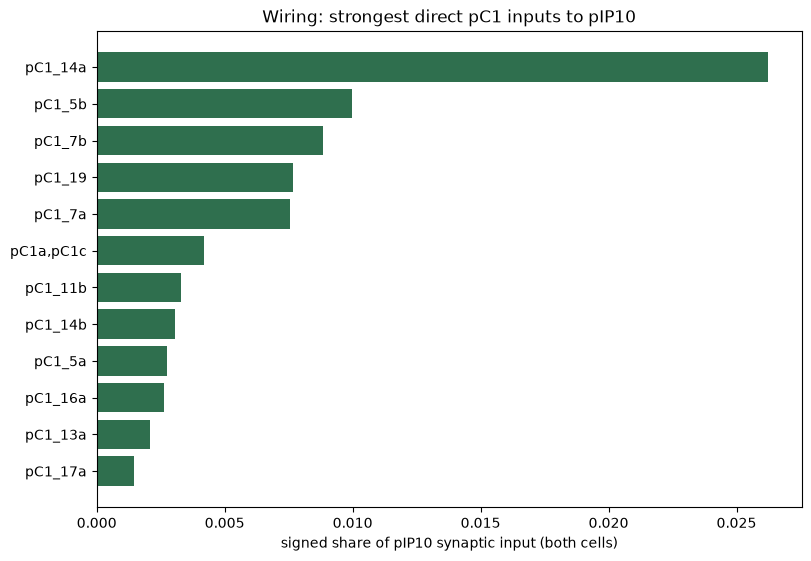

In [3]:

rows = ranked[:TOP_DIRECT_PLOT][::-1]
fig, ax = plt.subplots(figsize=(8, 5.5), constrained_layout=True)
colors = ["#c44536" if pip_share[typ] < 0 else "#2f6f4e" for typ in rows]
ax.barh(rows, [pip_share[typ] for typ in rows], color=colors)
ax.axvline(0, color="black", linewidth=0.6)
ax.set_xlabel("signed share of pIP10 synaptic input (both cells)")
ax.set_title("Wiring: strongest direct pC1 inputs to pIP10")
fig.savefig(FIG / "direct-pip10.png", dpi=140)
plt.show()


In [4]:

def trial(stim_idx, seed):
    brain.reset(int(seed))
    counts = {k: 0 for k in readouts}
    first = {k: -1 for k in readouts}
    hit = np.zeros(brain.n, np.bool_)
    for step in range(STEPS):
        if stim_idx is not None and ON <= step < OFF:
            brain.stimulate(stim_idx, STRENGTH)
        fired = brain.step()
        if ON <= step < OFF and len(fired):
            hit[:] = False
            hit[fired] = True
            for key, idx in readouts.items():
                m = hit[idx]
                counts[key] += int(m.sum())
                if first[key] < 0 and m.any():
                    first[key] = step
    dur = (OFF - ON) * brain.dt
    rates = {k: counts[k] / len(readouts[k]) / dur for k in readouts}
    latency = {k: (None if first[k] < 0 else (first[k] - ON) * brain.dt) for k in readouts}
    return rates, latency

def stack_rates(runs):
    return {k: np.array([r[k] for r in runs]) for k in readouts}

def stack_latency(runs):
    out = {}
    for k in readouts:
        vals = [r[k] for r in runs]
        fired = [v for v in vals if v is not None]
        out[k] = {
            "p_fire": len(fired) / len(vals),
            "latency_s": (None if not fired else float(np.median(fired))),
            "censored": len(vals) - len(fired),
        }
    return out

def run_condition(stim_idx, label):
    t0 = time.perf_counter()
    runs = [trial(stim_idx, seed) for seed in SEEDS]
    print(f"ran {label} ({0 if stim_idx is None else len(stim_idx)} neurons) in {time.perf_counter() - t0:.1f}s", flush=True)
    return stack_rates([r[0] for r in runs]), stack_latency([r[1] for r in runs])

t0 = time.perf_counter()
blank_rates, blank_lat = run_condition(None, "blank")

measured, latencies = {}, {}
stim_sets = {typ: neurons(typ) for typ in pc1_types}
for typ in pc1_types:
    measured[typ], latencies[typ] = run_condition(stim_sets[typ], typ)
measured["random"], latencies["random"] = run_condition(random_idx, "random cb_intrinsic")
print(f"intact-wiring simulation {time.perf_counter() - t0:.1f}s")

def stats(stim_rates):
    out = {}
    n = len(SEEDS)
    for key in readouts:
        d = stim_rates[key] - blank_rates[key]
        se = d.std(ddof=1) / np.sqrt(n)
        t = float(d.mean() / se) if se > 0 else 0.0
        out[key] = {
            "delta": float(d.mean()),
            "t": t,
            "blank": float(blank_rates[key].mean()),
            "moves": abs(float(d.mean())) >= MOVE_HZ and abs(t) >= MOVE_T,
        }
    return out

stim_stats = {typ: stats(measured[typ]) for typ in list(pc1_types) + ["random"]}

# Shuffled weights: permute synapse weights, keep every edge. Restore after.
original = np.array(brain.weights, copy=True)
perm = np.random.default_rng(SHUFFLE_SEED).permutation(original.size)
shuffled_stats = {}
shuffled_lat = {}
try:
    brain.weights[:] = original[perm]
    assert not np.array_equal(brain.weights, original)
    for label, idx in ((strong, neurons(strong)), (weak, neurons(weak)), ("random", random_idx)):
        rates, lat = run_condition(idx, f"shuffled {label}")
        shuffled_stats[label] = stats(rates)
        shuffled_lat[label] = lat
finally:
    brain.weights[:] = original
assert np.array_equal(brain.weights, original)
print("shuffled weights restored; indptr and indices were not modified")

def interesting(typ, key):
    share = direct_share[(typ, key)]
    moved = stim_stats[typ][key]["moves"]
    two = typ in two_pred[key]
    return abs(share) >= DIRECT_PREDICT or moved or two

print("\nComparison. agree = direct sign matches a detected move. floor = negative prediction but the blank is under 0.5 Hz.")
print("specific = |delta| exceeds the random-group |delta| by more than 1 Hz. Latency is the median time of the first spike in the injection window; censored seeds never spiked.")
print(f"{'stim':16s} {'readout':12s} {'share':8s} {'delta':8s} {'t':7s} {'blank':6s} {'rndΔ':8s} {'p':5s} {'lat_ms':7s} verdict")
for typ in ranked:
    for key in readouts:
        if not interesting(typ, key):
            continue
        share = direct_share[(typ, key)]
        st = stim_stats[typ][key]
        rnd = stim_stats["random"][key]["delta"]
        lat = latencies[typ][key]
        lat_ms = "cens" if lat["latency_s"] is None else f"{lat['latency_s'] * 1000:7.0f}"
        if abs(share) >= DIRECT_PREDICT:
            pred = np.sign(share)
            if pred < 0 and st["blank"] < 0.5:
                verdict = "floor"
            elif st["moves"] and np.sign(st["delta"]) == pred:
                verdict = "agree"
            elif st["moves"] and np.sign(st["delta"]) != pred:
                verdict = "disagree"
            else:
                verdict = "no-move"
        elif typ in two_pred[key]:
            pred = np.sign(two_score[(typ, key)])
            if pred < 0 and st["blank"] < 0.5:
                verdict = "two-floor"
            elif st["moves"] and np.sign(st["delta"]) == pred:
                verdict = "two-agree"
            elif st["moves"] and np.sign(st["delta"]) != pred:
                verdict = "two-disagree"
            else:
                verdict = "two-no-move"
        else:
            verdict = "unpredicted-move" if st["moves"] else "quiet"
        specific = abs(st["delta"]) > abs(rnd) + 1.0
        flag = "specific" if specific else "control-similar"
        print(f"{typ:16s} {key:12s} {share:+8.4f} {st['delta']:+8.2f} {st['t']:+7.1f} {st['blank']:6.2f} {rnd:+8.2f} {lat['p_fire']:5.2f} {lat_ms:>7s} {verdict:16s} {flag}")

print("\nRandom group, every readout that moves:")
any_rand = False
for key in readouts:
    st = stim_stats["random"][key]
    if st["moves"]:
        any_rand = True
        print(f"  {key:12s} delta {st['delta']:+6.2f} Hz  t={st['t']:+5.1f}  blank {st['blank']:.2f}")
if not any_rand:
    print("  none")

print("\nShuffled-weights rerun (seed 1). Same neurons, permuted synapse weights, edges unchanged.")
for label in (strong, weak, "random"):
    for key in readouts:
        base = stim_stats[label][key]
        sh = shuffled_stats[label][key]
        share = 0.0 if label == "random" else direct_share[(label, key)]
        if not (base["moves"] or sh["moves"] or abs(share) >= DIRECT_PREDICT):
            continue
        print(f"  {str(label):16s} {key:12s} intact {base['delta']:+7.2f} (t={base['t']:+5.1f}, moves={base['moves']})  shuffled {sh['delta']:+7.2f} (t={sh['t']:+5.1f}, moves={sh['moves']})")

n_direct = 0
n_agree = 0
n_move = 0
for typ in pc1_types:
    for key in readouts:
        share = direct_share[(typ, key)]
        st = stim_stats[typ][key]
        if st["moves"]:
            n_move += 1
        if abs(share) < DIRECT_PREDICT:
            continue
        n_direct += 1
        pred = np.sign(share)
        if st["moves"] and np.sign(st["delta"]) == pred:
            n_agree += 1
print(f"\nCounts: pC1 x readout pairs that move {n_move}; direct predictions (|share|>={DIRECT_PREDICT}) {n_direct}; of those, sign agrees {n_agree}.")
pip_movers = []
for typ in pc1_types:
    for key in pip_keys:
        st = stim_stats[typ][key]
        if st["moves"] and st["delta"] > 0:
            pip_movers.append(f"{typ}->{key} {st['delta']:+.2f} Hz")
print("pC1 types that raise a pIP10 side:", pip_movers if pip_movers else "none")

print("\nBlank P(fire) during the injection window:")
for key in readouts:
    print(f"  {key:12s} p={blank_lat[key]['p_fire']:.2f}  rate {blank_rates[key].mean():.2f} Hz")


ran blank (0 neurons) in 3.3s


ran pC1_10a (2 neurons) in 2.3s


ran pC1_10b (4 neurons) in 2.2s


ran pC1_10c (4 neurons) in 2.1s


ran pC1_10d (3 neurons) in 2.0s


ran pC1_11a (2 neurons) in 2.1s


... (44 outputs left out)

ran shuffled pC1_14a (6 neurons) in 2.4s


ran shuffled pC1_9b (2 neurons) in 2.3s


ran shuffled random (6 neurons) in 2.4s


shuffled weights restored; indptr and indices were not modified

Comparison. agree = direct sign matches a detected move. floor = negative prediction but the blank is under 0.5 Hz.
specific = |delta| exceeds the random-group |delta| by more than 1 Hz. Latency is the median time of the first spike in the injection window; censored seeds never spiked.
stim             readout      share    delta    t       blank  rndΔ     p     lat_ms  verdict
pC1_14a          pIP10-L       +0.0247    +1.00    +3.1   0.12    +0.12  0.75     210 agree            control-similar
pC1_14a          pIP10-R       +0.0278    +1.38    +5.2   0.62    -0.12  1.00     220 agree            specific
pC1_14a          pMP2-L        +0.0638    +3.50   +10.7   0.00    +0.00  1.00     180 agree            specific
pC1_14a          pMP2-R        +0.0510    +1.38    +4.2   0.00    +0.00  0.88     180 agree            specific
pC1_14a          vPR6-L        +0.0000    +0.00    +0.0   0.00    +0.00  0.00    cens two-no-move  

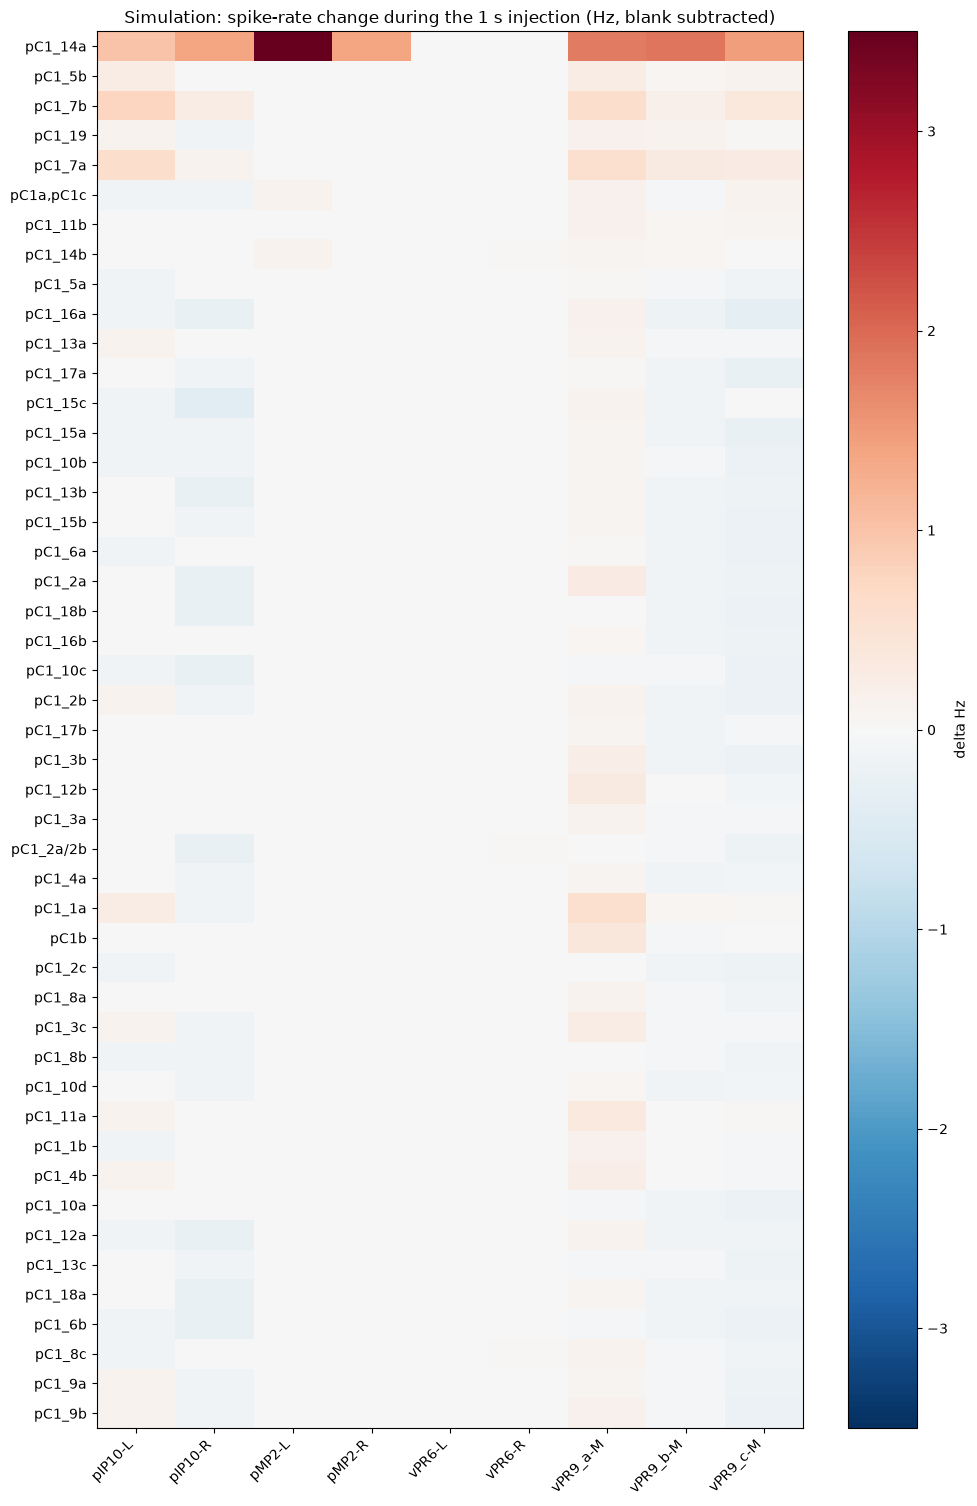

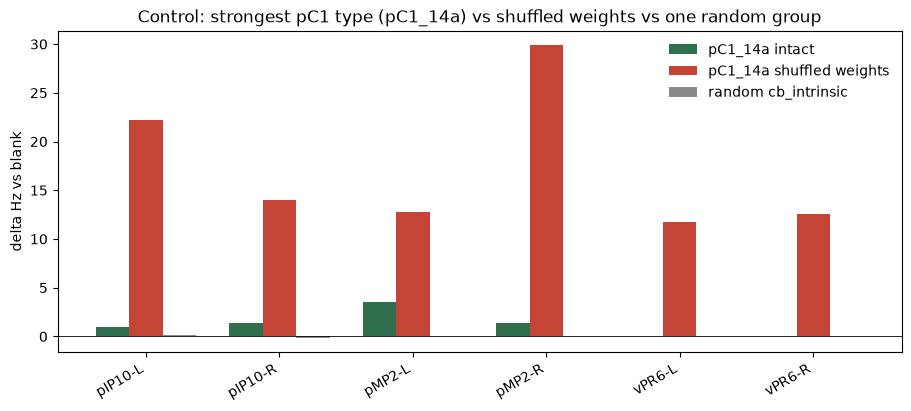

In [5]:

labels = ranked
keys = list(readouts)
mat = np.array([[stim_stats[typ][key]["delta"] for key in keys] for typ in labels])
fig, ax = plt.subplots(figsize=(10, 0.28 * len(labels) + 2))
limit = max(1.0, float(np.max(np.abs(mat))))
im = ax.imshow(mat, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(len(keys)), keys, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.set_title("Simulation: spike-rate change during the 1 s injection (Hz, blank subtracted)")
fig.colorbar(im, ax=ax, label="delta Hz")
fig.tight_layout()
fig.savefig(FIG / "rate-delta.png", dpi=140)
plt.show()

focus = ["pIP10-L", "pIP10-R", "pMP2-L", "pMP2-R", "vPR6-L", "vPR6-R"]
focus = [k for k in focus if k in readouts]
x = np.arange(len(focus))
width = 0.25
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
intact = [stim_stats[strong][k]["delta"] for k in focus]
shuff = [shuffled_stats[strong][k]["delta"] for k in focus]
rand = [stim_stats["random"][k]["delta"] for k in focus]
ax.bar(x - width, intact, width, label=f"{strong} intact", color="#2f6f4e")
ax.bar(x, shuff, width, label=f"{strong} shuffled weights", color="#c44536")
ax.bar(x + width, rand, width, label="random cb_intrinsic", color="#888888")
ax.axhline(0, color="black", linewidth=0.6)
ax.set_xticks(x, focus, rotation=30, ha="right")
ax.set_ylabel("delta Hz vs blank")
ax.set_title(f"Control: strongest pC1 type ({strong}) vs shuffled weights vs one random group")
ax.legend(frameon=False)
fig.savefig(FIG / "shuffle-control.png", dpi=140)
plt.show()


## How to read this, and what the papers say

**Wiring** above is the connectome. **Simulation** is the leaky integrate-and-fire model with the repository's default tonic and gain. A blank at the same noise seed is subtracted. "Moves" means the mean change is at least 1 Hz and the t-score (`mean / standard error`, 8 seeds) is at least 3, the bar in `inject.py`. A direct prediction exists only when that cell type supplies at least 1% of the readout's signed synaptic input. A negative prediction is **floor** when the blank rate is under 0.5 Hz, because this model cannot go below silence. A two-step prediction is one of the five largest absolute path products onto that readout, and only when the direct share is under 1%.

The random control is one draw (seed 0) of `cb_intrinsic` neurons that are not `pC1`, with the same count as the `pC1` type that has the largest absolute direct share onto `pIP10`. It is not redrawn per type. The other `pC1` types are the per-type control, because every type is stimulated. The shuffled-weights control permutes the values in `brain.weights` with seed 1 and does not change which neurons are connected. It is restored before the notebook ends.

Papers, as hypotheses:

- von Philipsborn et al. (2011), *Neuron* 69, 509–522. Activation of the descending neuron pIP10 elicits courtship song. This notebook cannot hear song. It can say whether a `pC1` type raises pIP10's spike rate.
- Shiozaki, Wang, Lillvis, Xu, Dickson and Stern (2024), *Nature Neuroscience* 27, 1954–1965, doi:10.1038/s41593-024-01738-9. pIP10 and pMP2 are the two descending pathways they recorded during song. pIP10 is active in pulse and sine song; pMP2 is pulse-selective. vPR9 is a ventral-nerve-cord neuron, recorded in the nerve cord, not a descending neuron. The superclass lines in the first code cell are the file's own labels for those names.
- Ahmed et al. (2023), bioRxiv, doi:10.1101/2023.11.07.566045, title "Transcriptional profiling of Drosophila male-specific P1 (pC1) neurons". That paper uses P1 and pC1 as one name for a cluster. It does not say which MaleCNS string (`pC1_14a`, `pC1a,pC1c`, and the rest) is P1. This file has no cell type named `P1`. The mapping is unresolved here, and this notebook does not guess one.
- The connectome is Berg et al. (2026), *Cell*, the MaleCNS release cited as reference 1 in the README.

What would count as reproducing the known circuit: a `pC1` type with a direct excitatory share onto pIP10 that raises pIP10 in the model, more than the random group, and that loses the effect when the synapse weights are permuted. What would count as failing it: no `pC1` type moves pIP10, or the move is matched by the random group, or it survives the weight permutation. vPR neurons are in this simulation only as `vnc_intrinsic` cells. A rate change there is a connectome path into the nerve cord, not evidence that the cell is a descending command, and not evidence of pulse versus sine song. There is no body, so nothing here is courtship behavior.

## What this run found

The numbers in the executed cells are the result. Seeds are 0 through 7. This is the reading of that output.

**Wiring.** `pC1_14a` (6 neurons, `cb_intrinsic`) has the largest direct share of any `pC1` type onto pIP10: +0.0262 pooled, +0.0247 on the left cell, +0.0278 on the right. It is also the largest direct share onto pMP2 (+0.0638 left, +0.0510 right). Every direct `pC1` share onto vPR6 and onto vPR9_a, vPR9_b and vPR9_c is 0 at four decimal places. The "top 8" lines for those readouts are the alphabetical head of a list of zeros, not a ranking of real synapses. Two-step products onto the vPR9 cells are nonzero and largest for `pC1_14a` (vPR9_b +0.00848, vPR9_c +0.00371, vPR9_a +0.00290). Two-step products onto vPR6 are under 0.001 in absolute value.

**Simulation, intact weights.** The only `pC1` type that moves a readout is `pC1_14a`. pIP10-L rises by +1.00 Hz (t=+3.1, blank 0.12 Hz, P(fire)=0.75, median first spike 210 ms). That clears the 1 Hz and t=3 bar and matches the excitatory share. It does not clear the extra specificity bar: the random group changes pIP10-L by +0.12 Hz, and the rule asks for more than 1 Hz beyond that, so the notebook marks pIP10-L `control-similar`. pIP10-R rises by +1.38 Hz (t=+5.2) and is marked `specific`. pMP2-L rises by +3.50 Hz (t=+10.7) and pMP2-R by +1.38 Hz (t=+4.2); both agree with the direct share and are specific. The same type raises vPR9_a, vPR9_b and vPR9_c by +1.81, +1.88 and +1.46 Hz with no direct synapse, in the same direction as the two-step product. vPR6 does not fire in the blank or under any intact `pC1` injection. Five direct predictions do not move the readout: `pC1_5b` onto pIP10-R (share +0.0121, delta 0), and `pC1a,pC1c` and `pC1_14b` onto pMP2 (shares about +0.011 to +0.018, delta at most +0.12 Hz). Of 9 direct predictions, 4 agree. Of the 47 types times 9 readouts, 7 pairs move, and all 7 are `pC1_14a`.

**Controls.** The random group (types CB.FB8B0, CB0926, CB1542, FS4B, KCg-d, SMP520b; neuron indices 2368, 18332, 22391, 48811, 72229, 124319) moves no readout. Permuting the synapse weights with seed 1 does not silence `pC1_14a`. `pC1_14a`, the near-zero type `pC1_9b`, and the random group then all drive these readouts by about +4 to +31 Hz. The intact weight values are what keep the response small and limited to `pC1_14a`. The permutation removes that selectivity. It is not evidence that a shuffled brain still sings.

**Against the papers.** `pC1_14a` raising pIP10 and pMP2 is the piece that lines up with those two descending song commands. vPR9 moving only through a two-step path, and only for that type, fits a nerve-cord cell rather than a direct `pC1` target. vPR6 is not moved. No cell type is named P1, so this file does not say which `pC1_*` string is P1. There is no song and no body.

Limits. Weights are normalized shares, not raw synapse counts. The step is 20 ms, so latency cannot be finer than that and the rate ceiling is 50 Hz. Photoreceptors are undriven. Tonic, gain and noise are the hand-set defaults, not fitted parameters. Eight seeds. One random draw. One weight permutation.

Rerun from a fresh install, after `flybrain download` (the first `FlyBrain()` does that, about 260 MB, sha256-checked). `nbconvert` uses the notebook's directory as the working directory, and the figures are written to `notebooks/courtship-figures/`.

```sh
pip install flybrain matplotlib
jupyter nbconvert --to notebook --execute --inplace notebooks/courtship.ipynb
```
